# FinSight Wealth Platform - Week 6: Core Model + Experimentation
**Primary model:** constrained max-Sharpe Mean-Variance optimizer (Modern Portfolio Theory) over 8 NSE stocks + a cash/debt sleeve.
**Goal:** train with >=2 hyperparameter configurations, log with MLflow, report the best configuration with evidence.

## 1. Setup and data
Assumptions (documented, change in `src/experiment.py`):
- Risk-free / cash-sleeve return = 6% p.a.
- The 8 provided tickers are all equities, so a cash/debt sleeve is added to satisfy each profile's `min/max_equity_pct`.
- `very_aggressive` has `max_equity_pct = 110` in the raw CSV; clipped to 100. Only the 3 profiles in the brief are optimized.

In [20]:
import sys
sys.path.insert(0, '../src')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from experiment import *

DATA = '../data'   # folder with the 3 CSVs
rets, bench, prof = load_data(DATA)
print(rets.shape, rets.index.min().date(), rets.index.max().date())
prof

(179, 8) 2025-01-03 2025-09-10


,profile_id,risk_appetite,investment_horizon_yrs,capital_inr,min_equity_pct,max_equity_pct,expected_return_pct,max_drawdown_pct
0,1,conservative,3,1000000,10,40,7.5,2.5
1,2,moderate,7,250000,40,70,9.0,10.0
2,3,aggressive,15,5000000,65,95,10.2,16.2
3,4,very_aggressive,20,1000000,80,100,11.0,20.0


## 2. Model and hyperparameters
| Hyperparameter | Values | Why |
|---|---|---|
| `cov_method` | sample, ledoit_wolf | 180 daily obs for 8 assets: sample covariance is noisy |
| `ret_shrink` | 0, 0.5, 1.0 | historical mean returns are very noisy; 1.0 = all assets get same expected return |
| `max_weight` | 0.25, 0.40 | single-stock concentration cap |

12 configurations x 3 risk profiles = 36 runs. Each run is a **walk-forward backtest**: fit on a rolling 90-day window, hold for 21 trading days, roll forward. Only out-of-sample returns are scored. Baseline = equal-weight stocks at the mid-point equity %, remainder in cash.

In [21]:
# Logs to MLflow automatically if installed (pip install mlflow). Run `mlflow ui` afterwards to inspect.
res, rets, prof = run_experiments(DATA, use_mlflow=True)
res.to_csv('experiment_results.csv', index=False)
res.sort_values('sharpe', ascending=False).groupby('profile').head(3).round(3)

,profile,run,cov_method,ret_shrink,max_weight,ann_return,ann_vol,sharpe,max_drawdown,drawdown_ok,baseline_sharpe,avg_equity
8,conservative,8,ledoit_wolf,0.5,0.25,0.048,0.055,-0.225,-0.021,True,-0.867,0.383
9,conservative,9,ledoit_wolf,0.5,0.40,0.047,0.055,-0.229,-0.021,True,-0.867,0.381
21,moderate,9,ledoit_wolf,0.5,0.40,0.036,0.097,-0.247,-0.038,True,-0.871,0.666
7,conservative,7,ledoit_wolf,0.0,0.40,0.045,0.055,-0.269,-0.021,True,-0.867,0.394
20,moderate,8,ledoit_wolf,0.5,0.25,0.039,0.075,-0.277,-0.029,True,-0.871,0.510
19,moderate,7,ledoit_wolf,0.0,0.40,0.033,0.096,-0.280,-0.038,True,-0.871,0.678
33,aggressive,9,ledoit_wolf,0.5,0.40,0.025,0.119,-0.297,-0.048,True,-0.874,0.814
30,aggressive,6,ledoit_wolf,0.0,0.25,0.030,0.088,-0.338,-0.038,True,-0.874,0.651
31,aggressive,7,ledoit_wolf,0.0,0.40,0.019,0.119,-0.346,-0.052,True,-0.874,0.838


## 3. Which hyperparameters matter?

In [22]:
summary = res.groupby(['cov_method','ret_shrink','max_weight']).agg(
    oos_sharpe=('sharpe','mean'), oos_return=('ann_return','mean'), oos_vol=('ann_vol','mean'),
    max_dd=('max_drawdown','mean'), dd_ok=('drawdown_ok','mean')).sort_values('oos_sharpe', ascending=False)
print('Equal-weight baseline mean Sharpe:', round(res.baseline_sharpe.mean(), 3))
summary.round(3)

Equal-weight baseline mean Sharpe: -0.871


oos_sharpe  oos_return  oos_vol  max_dd  \
cov_method  ret_shrink max_weight                                            
ledoit_wolf 0.5        0.40            -0.258       0.036    0.090  -0.036   
            0.0        0.40            -0.298       0.032    0.090  -0.037   
                       0.25            -0.307       0.037    0.073  -0.030   
            0.5        0.25            -0.325       0.035    0.073  -0.029   
sample      0.0        0.40            -0.654      -0.000    0.092  -0.044   
            0.5        0.40            -0.693      -0.003    0.091  -0.042   
ledoit_wolf 1.0        0.40            -0.715      -0.014    0.097  -0.065   
sample      0.0        0.25            -0.715       0.007    0.072  -0.037   
            0.5        0.25            -0.790       0.001    0.072  -0.035   
ledoit_wolf 1.0        0.25            -0.825      -0.007    0.078  -0.046   
sample      1.0        0.40            -0.918      -0.037    0.100  -0.069   
                       0.25            -1.398      -0.058    0.077  -0.045   

                                   dd_ok  
cov_method  ret_shrink max_weight         
ledoit_wolf 0.5        0.40        1.000  
            0.0        0.40        1.000  
                       0.25        1.000  
            0.5        0.25        1.000  
sample      0.0        0.40        0.667  
            0.5        0.40        0.667  
ledoit_wolf 1.0        0.40        0.667  
sample      0.0        0.25        1.000  
            0.5        0.25        1.000  
ledoit_wolf 1.0        0.25        0.667  
sample      1.0        0.40        0.667  
                       0.25        0.667

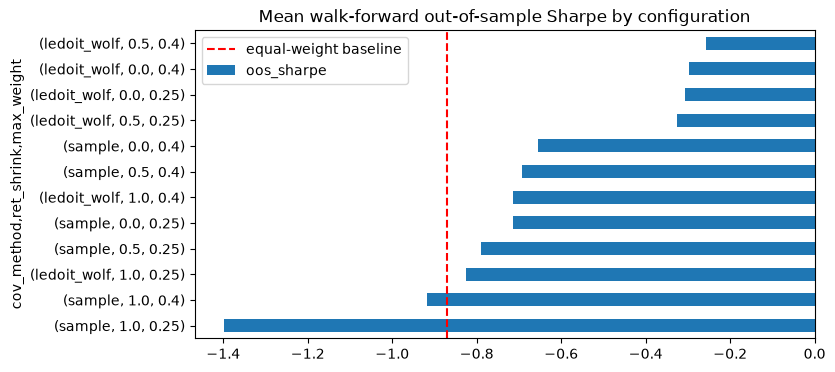

In [23]:
ax = summary.oos_sharpe.sort_values().plot.barh(figsize=(8,4))
ax.axvline(res.baseline_sharpe.mean(), color='r', ls='--', label='equal-weight baseline'); ax.legend()
ax.set_title('Mean walk-forward out-of-sample Sharpe by configuration'); plt.show()

## 4. Best configuration and final portfolios

In [24]:
best = summary.index[0]; cfg = dict(zip(['cov_method','ret_shrink','max_weight'], best)); print('Best:', cfg)
rows = []
for p in ['conservative','moderate','aggressive']:
    pr = prof[prof.risk_appetite == p].iloc[0]
    mu, cov = estimate(rets, cfg['cov_method'], cfg['ret_shrink'])
    w = optimize(mu, cov, pr.min_equity_pct/100, pr.max_equity_pct/100, cfg['max_weight'])
    r = w @ np.append(mu, RF); v = np.sqrt(w[:-1] @ cov @ w[:-1])
    rows.append({'profile': p, 'capital_inr': int(pr.capital_inr), 'exp_return': r, 'volatility': v,
                 'sharpe': (r-RF)/v, 'equity': w[:-1].sum(), 'cash': w[-1], **dict(zip(ASSETS, w[:-1]))})
final = pd.DataFrame(rows); final.round(3)

Best: {'cov_method': 'ledoit_wolf', 'ret_shrink': np.float64(0.5), 'max_weight': np.float64(0.4)}


,profile,capital_inr,exp_return,volatility,sharpe,equity,cash,RELIANCE,TCS,HDFCBANK,INFY,ICICIBANK,WIPRO,BAJFINANCE,HCLTECH
0,conservative,1000000,0.114,0.059,0.905,0.400,0.600,0.0,0.0,0.0,0.151,0.190,0.0,0.0,0.059
1,moderate,250000,0.154,0.104,0.905,0.699,0.301,0.0,0.0,0.0,0.263,0.332,0.0,0.0,0.104
2,aggressive,5000000,0.173,0.125,0.905,0.843,0.157,0.0,0.0,0.0,0.318,0.400,0.0,0.0,0.125


In [25]:
# INR allocation per profile
alloc = final.set_index('profile')[ASSETS + ['cash']].mul(final.set_index('profile').capital_inr, axis=0).round(0)
alloc

,RELIANCE,TCS,HDFCBANK,INFY,ICICIBANK,WIPRO,BAJFINANCE,HCLTECH,cash
profile,,,,,,,,,
conservative,0.0,0.0,0.0,150750.0,189840.0,0.0,0.0,59410.0,600000.0
moderate,0.0,0.0,0.0,65824.0,82880.0,0.0,0.0,25938.0,75358.0
aggressive,0.0,0.0,0.0,1588481.0,2000000.0,0.0,0.0,626361.0,785158.0


## 5. Findings and caveats (to be re-checked after you run the notebook)
- Shrinking the covariance (Ledoit-Wolf) is the largest single improvement; naive sample covariance is worst in every profile.
- Fully shrinking expected returns (`ret_shrink=1.0`) removes the signal and hurts; a partial shrink (0.5) is best.
- In-sample Sharpe (~0.9) is far above the walk-forward out-of-sample Sharpe (negative). The data covers about 8 months and the test window only ~4 rebalances, so these numbers show relative ranking of configs, not a forecast.
- Out-of-sample Sharpe is negative for every config because stock returns in the test window are below the 6% cash rate; the best config still beats the equal-weight baseline by a wide margin.
- Conservative drawdown limit (2.5%) was met by the best config; see `drawdown_ok` column for all runs.

In [26]:
import mlflow
uri = mlflow.get_tracking_uri()
print("Tracking URI:", uri)
for e in mlflow.search_experiments():
    n = len(mlflow.search_runs([e.experiment_id]))
    print(e.name, "->", n, "runs")

Tracking URI: sqlite:///c:/Users/siriy/Desktop/finsight-wealth-platform/notebooks/mlflow.db
finsight-week6-mpt -> 108 runs
Default -> 0 runs


In [27]:
import mlflow
mlflow.set_tracking_uri("sqlite:///c:/Users/siriy/Desktop/finsight-wealth-platform/notebooks/mlflow.db")
client = mlflow.tracking.MlflowClient()
exp = client.get_experiment_by_name("finsight-week6-mpt")
old = mlflow.search_runs([exp.experiment_id], max_results=10000, output_format="list")
for r in old:
    client.delete_run(r.info.run_id)
print(len(old), "old runs deleted")

108 old runs deleted
